# MoveEnetOFK paper assets — exact pipeline backend

This notebook generates publication-quality panels from one real event sample while using the **same C++ classes linked by `moveEnetOFK_offline.cpp`** for the algorithmic representations:

- `ev::offlineLoader<ev::AE>` for the `data.log` replay;
- `ev::EROS` with `init(width, height, 7, 0.3)`;
- `hpecore::SAE` with the packet timestamp used by the offline pipeline;
- `hpecore::pwtripletvelocity` for joint velocities;
- the same `CV_8U` conversion and `GaussianBlur(..., Size(5,5), ...)` applied before MoveEnet;
- the same MoveEnet checkpoint selection, used to generate the absolute 13-joint skeleton automatically.

The notebook compiles a tiny C++ dumper against the **installed `event-driven` and `hpe-core` libraries in the MoveEnetOFK container**. This avoids re-implementing EROS, SAE, or the triplet velocity estimator in Python and therefore follows the exact library versions used by the local build.

The exported figure panels are visualization-only views of those exact C++ states. Contrast stretching and SAE recency colouring never modify the underlying data used by the algorithm.

In [1]:
from pathlib import Path
import subprocess
import textwrap
import shutil
import math

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# ============================= USER CONFIGURATION =============================
# Any DHP19/eH36M event data.log accepted by moveEnetOFK_offline.cpp.
DATA_PATH = Path('/data/dhp19_testing_set_S13toS17/S13_1_1/ch2dvs/data.log')

# Optional pose source. If provided, use a MoveEnetOFK output CSV for the SAME sample.
# If left as None, the notebook automatically runs the same MoveEnet model/checkpoint
# used by moveEnetOFK_offline.cpp on the exact EROS transport frame selected below.
POSE_CSV = None  # e.g. Path('/data/.../MoveEnetOFK_output.csv')
AUTO_RUN_MOVENET = True
MOVENET_PYTHON = Path('/opt/venv/bin/python')
HPE_CORE_ROOT = Path('/usr/local/src/hpe-core')
MOVENET_GPU_ID = '0'   # '' forces CPU; '0' matches the default cuda:0 setup
MOVENET_CHECKPOINT = None  # None -> same DHP19/eH36M checkpoint selection as C++

# None -> automatically choose a representative dense event window.
TARGET_TIME_S = 9
VISIBLE_WINDOW_S = 0.5
AUTO_SELECTION_BORDER_FRACTION = 0.08

# Must match the operating point used for the flow visualization.
FLOW_PERIOD_S = 0.005
ROI_SIZE = 20

# None -> inferred as in the experimental setup: DHP19=346x260, eH36M=640x480.
SENSOR_SIZE = None

# Publication panels always show the complete sensor frame. No crop is applied.

# Current MoveEnetOFK pipeline constants.
EROS_KERNEL = 7
EROS_PARAMETER = 0.3
MOVENET_BLUR_KERNEL = 5

OUTPUT_DIR = Path('/tmp/moveenetofk_paper_assets_exact')
EXPORT_DPI = 350
MAX_3D_EVENTS = 45000

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Output directory:', OUTPUT_DIR)

Output directory: /tmp/moveenetofk_paper_assets_exact


## 1. Build the exact C++ extraction backend

The helper below does not reproduce the event representations approximately. It links against the same CMake targets as the paper executable (`ev::event-driven` and `hpe-core::hpe-core`) and calls the same classes directly.

In [2]:
CPP_SOURCE = r"""#include <event-driven/core.h>
#include <event-driven/algs.h>
#include <hpe-core/representations.h>
#include <hpe-core/motion.h>
#include <opencv2/opencv.hpp>

#include <algorithm>
#include <cmath>
#include <cstddef>
#include <filesystem>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <limits>
#include <sstream>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

namespace fs = std::filesystem;

struct PacketInfo {
    double ts{0.0};
    std::size_t count{0};
    std::size_t border_count{0};
};

struct EventRow {
    double ts{0.0};
    int x{0};
    int y{0};
    int p{0};
};

struct Args {
    std::string data_file;
    std::string out_dir;
    std::string pose_file;
    int width{346};
    int height{260};
    int transport_width{352};
    double target_time{-1.0};
    double window_s{0.05};
    double flow_period{0.005};
    int roi{20};
    int eros_kernel{7};
    double eros_parameter{0.3};
    int blur_kernel{5};
    double auto_border_fraction{0.08};
};

static Args parseArgs(int argc, char **argv) {
    Args a;
    for (int i = 1; i < argc; ++i) {
        const std::string key = argv[i];
        auto need = [&]() -> std::string {
            if (i + 1 >= argc) throw std::runtime_error("Missing value for " + key);
            return argv[++i];
        };
        if (key == "--data_file") a.data_file = need();
        else if (key == "--out_dir") a.out_dir = need();
        else if (key == "--pose_file") a.pose_file = need();
        else if (key == "--w") a.width = std::stoi(need());
        else if (key == "--h") a.height = std::stoi(need());
        else if (key == "--transport_w") a.transport_width = std::stoi(need());
        else if (key == "--target_time") a.target_time = std::stod(need());
        else if (key == "--window_s") a.window_s = std::stod(need());
        else if (key == "--flow_period") a.flow_period = std::stod(need());
        else if (key == "--roi") a.roi = std::stoi(need());
        else if (key == "--eros_kernel") a.eros_kernel = std::stoi(need());
        else if (key == "--eros_parameter") a.eros_parameter = std::stod(need());
        else if (key == "--blur_kernel") a.blur_kernel = std::stoi(need());
        else if (key == "--auto_border_fraction") a.auto_border_fraction = std::stod(need());
        else throw std::runtime_error("Unknown argument: " + key);
    }
    if (a.data_file.empty() || a.out_dir.empty()) {
        throw std::runtime_error("--data_file and --out_dir are required");
    }
    return a;
}

static std::vector<PacketInfo> scanPackets(
    const std::string &path,
    int width,
    int height,
    double border_fraction
) {
    ev::offlineLoader<ev::AE> loader;
    if (!loader.load(path)) throw std::runtime_error("Could not load " + path);

    constexpr double eps = 1e-6;
    double next_packet_ts = 0.0;
    std::vector<PacketInfo> packets;

    const int bx = std::max(1, static_cast<int>(std::round(width * border_fraction)));
    const int by = std::max(1, static_cast<int>(std::round(height * border_fraction)));

    while (loader.incrementReadTill(next_packet_ts)) {
        if (loader.begin() == loader.end()) {
            next_packet_ts += eps;
            continue;
        }
        const double packet_ts = loader.begin().timestamp();
        std::size_t n = 0;
        std::size_t border_n = 0;
        for (auto v = loader.begin(); v != loader.end(); ++v) {
            ++n;
            const int x = static_cast<int>(v->x);
            const int y = static_cast<int>(v->y);
            if (x < bx || x >= width - bx || y < by || y >= height - by) {
                ++border_n;
            }
        }
        packets.push_back({packet_ts, n, border_n});
        next_packet_ts = packet_ts + eps;
    }
    if (packets.empty()) throw std::runtime_error("No event packets found");
    return packets;
}

static double bestVisibleWindowTarget(const std::vector<PacketInfo> &packets, double window_s) {
    std::size_t left = 0;
    std::size_t count = 0;
    std::size_t border_count = 0;
    double best_score = -1.0;
    std::size_t best_count = 0;
    std::size_t best_left = 0;
    std::size_t best_right = 0;

    for (std::size_t right = 0; right < packets.size(); ++right) {
        count += packets[right].count;
        border_count += packets[right].border_count;
        while (left < right && packets[right].ts - packets[left].ts > window_s) {
            count -= packets[left].count;
            border_count -= packets[left].border_count;
            ++left;
        }

        if (count == 0) continue;
        const double border_fraction = static_cast<double>(border_count) / static_cast<double>(count);
        const double interior_fraction = std::max(0.0, 1.0 - border_fraction);

        // Prefer a dense event window, but strongly discourage frames in which the
        // moving subject is touching the sensor boundary. This is only used to pick
        // a representative paper timestamp; event replay itself remains unchanged.
        const double score = static_cast<double>(count) * std::pow(interior_fraction, 3.0);

        if (score > best_score || (std::abs(score - best_score) < 1e-12 && count > best_count)) {
            best_score = score;
            best_count = count;
            best_left = left;
            best_right = right;
        }
    }
    return 0.5 * (packets[best_left].ts + packets[best_right].ts);
}

static std::vector<double> flowUpdateTimes(const std::vector<PacketInfo> &packets, double flow_period) {
    std::vector<double> out;
    double next_flow_upd = 0.0;
    for (const auto &p : packets) {
        if (p.ts >= next_flow_upd) {
            out.push_back(p.ts);
            next_flow_upd = flow_period + p.ts; // identical scheduler update used by moveEnetOFK_offline.cpp
        }
    }
    return out;
}

static std::pair<double,double> snapToFlowUpdate(const std::vector<double> &flow_times, double target) {
    if (flow_times.empty()) return {target, target};
    auto it = std::lower_bound(flow_times.begin(), flow_times.end(), target);
    std::size_t idx = 0;
    if (it == flow_times.begin()) idx = 0;
    else if (it == flow_times.end()) idx = flow_times.size() - 1;
    else {
        const std::size_t hi = static_cast<std::size_t>(it - flow_times.begin());
        const std::size_t lo = hi - 1;
        idx = (std::abs(flow_times[hi] - target) < std::abs(flow_times[lo] - target)) ? hi : lo;
    }
    const double cur = flow_times[idx];
    const double prev = (idx > 0) ? flow_times[idx - 1] : cur;
    return {cur, prev};
}

static void writeMat64(const cv::Mat &input, const fs::path &path) {
    cv::Mat m;
    input.convertTo(m, CV_64F);
    std::ofstream out(path, std::ios::binary);
    if (!out) throw std::runtime_error("Could not write " + path.string());
    for (int y = 0; y < m.rows; ++y) {
        out.write(reinterpret_cast<const char *>(m.ptr<double>(y)), sizeof(double) * m.cols);
    }
}

static bool readPose(const std::string &path, hpecore::skeleton13 &pose) {
    if (path.empty()) return false;
    std::ifstream in(path);
    if (!in) return false;
    for (int j = 0; j < 13; ++j) {
        double x = 0.0, y = 0.0;
        if (!(in >> x >> y)) return false;
        pose[j] = {static_cast<float>(x), static_cast<float>(y)};
    }
    return true;
}

int main(int argc, char **argv) {
    try {
        const Args a = parseArgs(argc, argv);
        fs::create_directories(a.out_dir);

        const auto packets = scanPackets(a.data_file, a.width, a.height, a.auto_border_fraction);
        const double candidate = (a.target_time >= 0.0)
            ? a.target_time
            : bestVisibleWindowTarget(packets, a.window_s);

        const auto flow_times = flowUpdateTimes(packets, a.flow_period);
        const auto [flow_ts, prev_flow_ts] = snapToFlowUpdate(flow_times, candidate);

        ev::EROS eros;
        eros.init(a.width, a.height, a.eros_kernel, a.eros_parameter);

        hpecore::SAE sae;
        sae.init(a.width, a.height);

        ev::offlineLoader<ev::AE> loader;
        if (!loader.load(a.data_file)) throw std::runtime_error("Could not reload data");

        constexpr double eps = 1e-6;
        double next_packet_ts = 0.0;
        const double event_lo = flow_ts - 0.5 * a.window_s;
        const double event_hi = flow_ts + 0.5 * a.window_s;
        std::vector<EventRow> visible_events;
        std::size_t replayed_events = 0;

        while (loader.incrementReadTill(next_packet_ts)) {
            if (loader.begin() == loader.end()) {
                next_packet_ts += eps;
                continue;
            }

            const double packet_ts = loader.begin().timestamp();
            const bool update_state = packet_ts <= flow_ts + 1e-12;
            const bool collect = packet_ts >= event_lo && packet_ts <= event_hi;

            for (auto v = loader.begin(); v != loader.end(); ++v) {
                if (update_state) {
                    eros.update(v->x, v->y);
                    sae.update(v->x, v->y, packet_ts);
                    ++replayed_events;
                }
                if (collect) {
                    visible_events.push_back({packet_ts, static_cast<int>(v->x), static_cast<int>(v->y), static_cast<int>(v->p)});
                }
            }

            next_packet_ts = packet_ts + eps;
            if (packet_ts > event_hi && packet_ts > flow_ts) break;
        }

        const cv::Mat eros_surface = eros.getSurface().clone();
        const cv::Mat sae_surface = sae.getSurface().clone();

        writeMat64(eros_surface, fs::path(a.out_dir) / "eros.bin");
        writeMat64(sae_surface, fs::path(a.out_dir) / "sae.bin");

        // Exact preparation performed by offlineDetector::update before YARP transmission.
        cv::Mat eros_u8;
        eros_surface.convertTo(eros_u8, CV_8U);
        cv::GaussianBlur(eros_u8, eros_u8, cv::Size(a.blur_kernel, a.blur_kernel), 0, 0);
        cv::imwrite((fs::path(a.out_dir) / "eros_movenet_input_exact.png").string(), eros_u8);

        cv::Mat transport = eros_u8;
        if (a.transport_width > eros_u8.cols) {
            transport = cv::Mat::zeros(eros_u8.rows, a.transport_width, CV_8U);
            eros_u8.copyTo(transport(cv::Rect(0, 0, eros_u8.cols, eros_u8.rows)));
        } else if (a.transport_width > 0 && a.transport_width != eros_u8.cols) {
            cv::resize(eros_u8, transport, cv::Size(a.transport_width, eros_u8.rows), 0, 0, cv::INTER_AREA);
        }
        cv::imwrite((fs::path(a.out_dir) / "eros_transport_exact.png").string(), transport);

        {
            std::ofstream out(fs::path(a.out_dir) / "events.csv");
            out << "timestamp,x,y,polarity\n";
            out << std::setprecision(12);
            for (const auto &e : visible_events) {
                out << e.ts << ',' << e.x << ',' << e.y << ',' << e.p << '\n';
            }
        }

        hpecore::skeleton13 pose;
        const bool have_pose = readPose(a.pose_file, pose);
        bool have_velocities = false;
        hpecore::skeleton13 velocities{};
        if (have_pose) {
            hpecore::pwtripletvelocity estimator;
            estimator.prev_update_ts = prev_flow_ts;
            velocities = estimator.multi_area_velocity(sae_surface, flow_ts, pose, a.roi);
            have_velocities = true;

            std::ofstream out(fs::path(a.out_dir) / "velocities.csv");
            out << "joint,x,y,vx,vy\n";
            out << std::setprecision(12);
            for (int j = 0; j < 13; ++j) {
                out << j << ',' << pose[j].u << ',' << pose[j].v << ','
                    << velocities[j].u << ',' << velocities[j].v << '\n';
            }
        }

        double eros_min = 0.0, eros_max = 0.0;
        cv::minMaxLoc(eros_surface, &eros_min, &eros_max);
        double sae_min = 0.0, sae_max = 0.0;
        cv::minMaxLoc(sae_surface, &sae_min, &sae_max);
        double input_min = 0.0, input_max = 0.0;
        cv::minMaxLoc(eros_u8, &input_min, &input_max);

        std::ofstream meta(fs::path(a.out_dir) / "metadata.txt");
        meta << std::setprecision(12);
        meta << "candidate_time=" << candidate << '\n';
        meta << "selected_flow_time=" << flow_ts << '\n';
        meta << "previous_flow_time=" << prev_flow_ts << '\n';
        meta << "flow_period=" << a.flow_period << '\n';
        meta << "width=" << a.width << '\n';
        meta << "height=" << a.height << '\n';
        meta << "transport_width=" << a.transport_width << '\n';
        meta << "visible_events=" << visible_events.size() << '\n';
        meta << "replayed_events=" << replayed_events << '\n';
        meta << "eros_min=" << eros_min << '\n';
        meta << "eros_max=" << eros_max << '\n';
        meta << "sae_min=" << sae_min << '\n';
        meta << "sae_max=" << sae_max << '\n';
        meta << "movenet_input_min=" << input_min << '\n';
        meta << "movenet_input_max=" << input_max << '\n';
        meta << "pose_available=" << (have_pose ? 1 : 0) << '\n';
        meta << "velocity_available=" << (have_velocities ? 1 : 0) << '\n';

        std::cout << "Selected flow timestamp: " << std::setprecision(12) << flow_ts << std::endl;
        std::cout << "Events in visible window: " << visible_events.size() << std::endl;
        std::cout << "EROS range from linked library: [" << eros_min << ", " << eros_max << "]" << std::endl;
        return 0;
    } catch (const std::exception &e) {
        std::cerr << "ERROR: " << e.what() << std::endl;
        return 1;
    }
}
"""
CMAKE_SOURCE = r"""cmake_minimum_required(VERSION 3.16)
project(moveenet_asset_dump LANGUAGES CXX)
set(CMAKE_CXX_STANDARD 17)
set(CMAKE_CXX_STANDARD_REQUIRED ON)
find_package(OpenCV REQUIRED)
find_package(event-driven REQUIRED)
find_package(hpe-core REQUIRED)
add_executable(moveenet_asset_dump main.cpp)
target_link_libraries(moveenet_asset_dump PRIVATE
    ${OpenCV_LIBS}
    ev::event-driven
    hpe-core::hpe-core
)
"""

BACKEND_DIR = OUTPUT_DIR / '_cpp_backend'
BUILD_DIR = BACKEND_DIR / 'build'
BACKEND_DIR.mkdir(parents=True, exist_ok=True)
(BACKEND_DIR / 'main.cpp').write_text(CPP_SOURCE)
(BACKEND_DIR / 'CMakeLists.txt').write_text(CMAKE_SOURCE)

subprocess.run(['cmake', '-S', str(BACKEND_DIR), '-B', str(BUILD_DIR), '-DCMAKE_BUILD_TYPE=Release'], check=True)
subprocess.run(['cmake', '--build', str(BUILD_DIR), '-j2'], check=True)
BACKEND_EXE = BUILD_DIR / 'moveenet_asset_dump'
print('Exact backend:', BACKEND_EXE)

-- Found YARP: /usr/local/lib/cmake/YARP (found version "3.7.2")
-- Configuring done
-- Generating done
-- Build files have been written to: /tmp/moveenetofk_paper_assets_exact/_cpp_backend/build
Scanning dependencies of target moveenet_asset_dump
[ 50%] Building CXX object CMakeFiles/moveenet_asset_dump.dir/main.cpp.o
[100%] Linking CXX executable moveenet_asset_dump
[100%] Built target moveenet_asset_dump
Exact backend: /tmp/moveenetofk_paper_assets_exact/_cpp_backend/build/moveenet_asset_dump


## 2. Run the same replay path used by `moveEnetOFK_offline.cpp`

The selected timestamp is snapped to an actual flow-update packet according to the same scheduler rule used by the executable (`next_flow_upd = flow_period + tnow`). The C++ helper then replays events packet-by-packet and dumps the exact EROS and SAE matrices.

If `POSE_CSV` is supplied, the closest 13-joint pose is used only as the ROI location; the velocity vectors themselves are recomputed by `hpecore::pwtripletvelocity` from the exact SAE.

In [3]:
def infer_geometry(path, sensor_size=None):
    if sensor_size is not None:
        w, h = map(int, sensor_size)
    else:
        p = str(path).lower()
        if 'dhp19' in p or 'ch2dvs' in p or 'ch3dvs' in p:
            w, h = 346, 260
        else:
            w, h = 640, 480
    transport_w = 352 if (w, h) == (346, 260) else w
    return w, h, transport_w


def read_metadata(path):
    meta = {}
    for line in Path(path).read_text().splitlines():
        if '=' not in line:
            continue
        k, v = line.split('=', 1)
        try:
            meta[k] = float(v)
        except ValueError:
            meta[k] = v
    return meta


def run_exact_backend(target_time, pose_file=None):
    w, h, transport_w = infer_geometry(DATA_PATH, SENSOR_SIZE)
    cmd = [
        str(BACKEND_EXE),
        '--data_file', str(DATA_PATH),
        '--out_dir', str(OUTPUT_DIR),
        '--w', str(w), '--h', str(h), '--transport_w', str(transport_w),
        '--target_time', str(-1.0 if target_time is None else float(target_time)),
        '--window_s', str(VISIBLE_WINDOW_S),
        '--flow_period', str(FLOW_PERIOD_S),
        '--roi', str(ROI_SIZE),
        '--eros_kernel', str(EROS_KERNEL),
        '--eros_parameter', str(EROS_PARAMETER),
        '--blur_kernel', str(MOVENET_BLUR_KERNEL),
        '--auto_border_fraction', str(AUTO_SELECTION_BORDER_FRACTION),
    ]
    if pose_file is not None:
        cmd += ['--pose_file', str(pose_file)]
    subprocess.run(cmd, check=True)
    return read_metadata(OUTPUT_DIR / 'metadata.txt')


if not DATA_PATH.exists():
    raise FileNotFoundError(f'DATA_PATH does not exist: {DATA_PATH}')

# Pass 1: choose/snap the exact event timestamp and dump surfaces.
meta = run_exact_backend(TARGET_TIME_S)
SELECTED_TIME = float(meta['selected_flow_time'])
WIDTH = int(meta['width'])
HEIGHT = int(meta['height'])
print('Selected timestamp:', SELECTED_TIME)
print('Exact EROS range:', meta['eros_min'], '->', meta['eros_max'])
print('Exact MoveEnet input range after CV_8U + blur:', meta['movenet_input_min'], '->', meta['movenet_input_max'])

Selected flow timestamp: 8.999237
Events in visible window: 12656
EROS range from linked library: [0, 255]
Selected timestamp: 8.999237
Exact EROS range: 0.0 -> 255.0
Exact MoveEnet input range after CV_8U + blur: 0.0 -> 116.0


## 3. MoveEnet pose, skeleton, and exact joint velocities

If `POSE_CSV` is supplied, the closest pose row is used. Otherwise, with `AUTO_RUN_MOVENET=True`, the notebook runs the same hpe-core MoveEnet model and the same checkpoint selected by `moveEnetOFK_offline.cpp` on the exact EROS transport frame. This produces the 13-joint detection needed both for the standalone skeleton asset and for the optical-flow ROIs.

The velocity vectors are then recomputed by the exact C++ `hpecore::pwtripletvelocity::multi_area_velocity(...)` call from the exact SAE.


In [4]:
POSE = None
POSE_CONFIDENCE = None
VELOCITIES = None
pose_file = None
POSE_SOURCE = None


def _default_checkpoint():
    is_dhp19 = (WIDTH, HEIGHT) == (346, 260)
    if is_dhp19:
        return HPE_CORE_ROOT / 'example/movenet/models/dhp19_allcams_e33_valacc0.87996.pth'
    return HPE_CORE_ROOT / 'example/movenet/models/e97_valacc0.81209.pth'


def _run_movenet_direct():
    """Run the same hpe-core MoveEnet inference path on the exact transport frame."""
    python_exe = Path(MOVENET_PYTHON)
    if not python_exe.exists():
        raise FileNotFoundError(f'MoveEnet Python interpreter not found: {python_exe}')
    if not HPE_CORE_ROOT.exists():
        raise FileNotFoundError(f'hpe-core not found: {HPE_CORE_ROOT}')

    checkpoint = Path(MOVENET_CHECKPOINT) if MOVENET_CHECKPOINT is not None else _default_checkpoint()
    if not checkpoint.exists():
        raise FileNotFoundError(f'MoveEnet checkpoint not found: {checkpoint}')

    input_png = OUTPUT_DIR / 'eros_transport_exact.png'
    output_csv = OUTPUT_DIR / '_movenet_pose_direct.csv'
    runner = OUTPUT_DIR / '_run_exact_movenet_pose.py'

    runner.write_text(r'''
import copy
import csv
import sys
from pathlib import Path

import cv2
import numpy as np

hpe_root = Path(sys.argv[1])
checkpoint = Path(sys.argv[2])
input_png = Path(sys.argv[3])
output_csv = Path(sys.argv[4])
gpu_id = sys.argv[5]
sensor_w = int(sys.argv[6])
sensor_h = int(sys.argv[7])

sys.path.insert(0, str(hpe_root))
sys.path.insert(0, str(hpe_root / 'example/movenet'))

from config import cfg as base_cfg
from pycore.moveenet import MoveNet, Task

cfg = copy.deepcopy(base_cfg)
cfg['GPU_ID'] = gpu_id
cfg['cfg_verbose'] = False
cfg['write_output'] = False
cfg['num_classes'] = 13
cfg['width_mult'] = 1.0
cfg['img_size'] = 192

img = cv2.imread(str(input_png), cv2.IMREAD_GRAYSCALE)
if img is None:
    raise RuntimeError(f'Could not read exact MoveEnet input: {input_png}')

model = MoveNet(num_classes=cfg['num_classes'], width_mult=cfg['width_mult'], mode='train')
task = Task(cfg, model)
task.modelLoad(str(checkpoint))
result = task.predict_online(img)

pose = np.asarray(result['joints'], dtype=float).reshape(13, 2)
confidence = np.asarray(result['confidence'], dtype=float).reshape(13)

# moveEnetOFK_offline.cpp clamps the returned transport-frame coordinates
# to the logical sensor canvas when DHP19 uses 352-pixel YARP transport.
pose[:, 0] = np.clip(pose[:, 0], 0, sensor_w - 1)
pose[:, 1] = np.clip(pose[:, 1], 0, sensor_h - 1)

with output_csv.open('w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['joint', 'x', 'y', 'confidence'])
    for j in range(13):
        w.writerow([j, pose[j,0], pose[j,1], confidence[j]])
''')

    cmd = [
        str(python_exe), str(runner), str(HPE_CORE_ROOT), str(checkpoint),
        str(input_png), str(output_csv), str(MOVENET_GPU_ID), str(WIDTH), str(HEIGHT)
    ]
    print('Running MoveEnet for the selected EROS frame...')
    subprocess.run(cmd, check=True)
    out = pd.read_csv(output_csv)
    pose = out[['x', 'y']].to_numpy(float)
    confidence = out['confidence'].to_numpy(float)
    return pose, confidence, checkpoint


if POSE_CSV is not None:
    pose_csv_path = Path(POSE_CSV)
    if not pose_csv_path.exists():
        raise FileNotFoundError(f'POSE_CSV does not exist: {pose_csv_path}')
    df_pose = pd.read_csv(pose_csv_path)
    if 'timestamp' not in df_pose.columns:
        raise ValueError('POSE_CSV must contain a timestamp column')
    required = [f'joint{j}_{a}' for j in range(13) for a in ('x', 'y')]
    missing = [c for c in required if c not in df_pose.columns]
    if missing:
        raise ValueError(f'POSE_CSV is missing columns: {missing}')

    ridx = int(np.argmin(np.abs(df_pose['timestamp'].to_numpy(float) - SELECTED_TIME)))
    row = df_pose.iloc[ridx]
    POSE = np.asarray([[float(row[f'joint{j}_x']), float(row[f'joint{j}_y'])] for j in range(13)], dtype=float)
    conf_cols = [f'joint{j}_conf' for j in range(13)]
    if all(c in df_pose.columns for c in conf_cols):
        POSE_CONFIDENCE = np.asarray([float(row[c]) for c in conf_cols], dtype=float)
    POSE_SOURCE = f'CSV: {pose_csv_path}'
    print('Pose timestamp:', float(row['timestamp']))

elif AUTO_RUN_MOVENET:
    POSE, POSE_CONFIDENCE, used_checkpoint = _run_movenet_direct()
    POSE_SOURCE = f'MoveEnet: {used_checkpoint.name}'
    print('Pose generated directly by MoveEnet using:', used_checkpoint)

else:
    print('No pose source configured. Set POSE_CSV or AUTO_RUN_MOVENET=True.')


if POSE is not None:
    pose_file = OUTPUT_DIR / '_pose_for_exact_flow.txt'
    np.savetxt(pose_file, POSE, fmt='%.12f')

    # Same replay, now evaluating the exact pwtripletvelocity around the 13 ROIs.
    meta = run_exact_backend(SELECTED_TIME, pose_file=pose_file)
    vel_df = pd.read_csv(OUTPUT_DIR / 'velocities.csv')
    POSE = vel_df[['x', 'y']].to_numpy(float)
    VELOCITIES = vel_df[['vx', 'vy']].to_numpy(float)
    print('Velocity vectors recomputed by C++:', len(VELOCITIES))
    print('Pose source:', POSE_SOURCE)


Running MoveEnet for the selected EROS frame...
cuda
/usr/local/src/hpe-core/example/movenet/models/dhp19_allcams_e33_valacc0.87996.pth


/opt/venv/lib/python3.8/site-packages/torch/nn/_reduction.py:42: UserWarning: size_average and reduce args will be deprecated, please use reduction='mean' instead.
  warnings.warn(warning.format(ret))
/usr/local/src/hpe-core/pycore/moveenet/task/task.py:345: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where yo

Pose generated directly by MoveEnet using: /usr/local/src/hpe-core/example/movenet/models/dhp19_allcams_e33_valacc0.87996.pth
Selected flow timestamp: 8.999237
Events in visible window: 12656
EROS range from linked library: [0, 255]
Velocity vectors recomputed by C++: 13
Pose source: MoveEnet: dhp19_allcams_e33_valacc0.87996.pth


## 4. Load the exact dumped states and use the complete sensor frame

No spatial crop is applied anywhere in the notebook. All 2-D panels use the full native sensor canvas: **346×260 for DHP19** or **640×480 for eH36M**. The optical-flow panel also uses the complete frame and does not draw an ROI/bounding box.


In [5]:
events = pd.read_csv(OUTPUT_DIR / 'events.csv')
if len(events) == 0:
    raise RuntimeError('No events were found around the selected timestamp.')

EROS = np.fromfile(OUTPUT_DIR / 'eros.bin', dtype=np.float64).reshape(HEIGHT, WIDTH)
SAE = np.fromfile(OUTPUT_DIR / 'sae.bin', dtype=np.float64).reshape(HEIGHT, WIDTH)
EROS_INPUT_EXACT = cv2.imread(str(OUTPUT_DIR / 'eros_movenet_input_exact.png'), cv2.IMREAD_GRAYSCALE)
EROS_TRANSPORT_EXACT = cv2.imread(str(OUTPUT_DIR / 'eros_transport_exact.png'), cv2.IMREAD_GRAYSCALE)


# Full native sensor frame for every publication panel.
# Coordinates follow the original event-camera canvas; nothing is cropped or padded.
CROP = (0, WIDTH, 0, HEIGHT)
print('Publication frame [x0,x1,y0,y1]:', CROP)

def crop_img(img, crop=CROP, pad_value=0):
    """Compatibility helper: return the complete sensor image unchanged."""
    return img

def sae_recency_image(sae, now, max_age=None):
    valid = sae > 0
    age = np.full_like(sae, np.nan, dtype=float)
    age[valid] = np.maximum(now - sae[valid], 0.0)
    finite = age[np.isfinite(age)]
    if max_age is None:
        max_age = max(FLOW_PERIOD_S * 8.0, np.quantile(finite, 0.98) if finite.size else FLOW_PERIOD_S)
    tau = max(max_age / 3.0, 1e-9)
    out = np.zeros_like(sae, dtype=float)
    out[valid] = np.exp(-age[valid] / tau)
    return out

SAE_RECENCY = sae_recency_image(SAE, SELECTED_TIME)

Publication frame [x0,x1,y0,y1]: (0, 346, 0, 260)


## 5. Export publication panels

Two EROS views are exported on purpose:

- `04_eros_movenet_input_exact.png` preserves the exact 8-bit values transmitted by the C++ preprocessing path;
- `04b_eros_movenet_input_display.png` applies only a display contrast stretch so that the same signal is easier to read in a paper figure.

For the paper diagram, the display version is usually clearer while still depicting the exact underlying frame.

In [6]:
POS_COLOR = '#e31a1c'
NEG_COLOR = '#2166ac'
SKELETON_COLOR = '#2b2b2b'
JOINT_COLOR = '#2f80ed'

# hpe-core 13-joint topology (head=0 is intentionally an unconnected keypoint).
SKELETON_EDGES = [
    (1,3), (3,7),
    (2,4), (4,8),
    (1,2),
    (1,6), (2,5), (6,5),
    (6,9), (9,11),
    (5,10), (10,12),
]


def save_fig(fig, filename, transparent=False):
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=EXPORT_DPI, bbox_inches='tight', pad_inches=0.02,
                transparent=transparent)
    plt.close(fig)
    return path


def contrast_stretch_u8(img):
    vals = img[img > 0]
    if vals.size == 0:
        return img.copy()
    lo, hi = np.quantile(vals, [0.01, 0.995])
    if hi <= lo:
        hi = lo + 1.0
    out = np.clip((img.astype(float) - lo) / (hi - lo), 0, 1)
    return np.uint8(np.round(out * 255.0))


def draw_skeleton(ax, pose, edge_color=SKELETON_COLOR, joint_color=JOINT_COLOR,
                  line_width=3.0, joint_size=46, show_head_connection=True):
    valid = np.isfinite(pose).all(axis=1) & (pose[:,0] >= 0) & (pose[:,1] >= 0)
    for a, b in SKELETON_EDGES:
        if valid[a] and valid[b]:
            ax.plot(pose[[a,b],0], pose[[a,b],1], '-', lw=line_width,
                    color=edge_color, solid_capstyle='round', zorder=3)
    # For diagram readability only: connect the head to the midpoint of the shoulders.
    # The detected head coordinate remains the actual MoveEnet keypoint.
    if show_head_connection and valid[0] and valid[1] and valid[2]:
        neck = 0.5 * (pose[1] + pose[2])
        ax.plot([pose[0,0], neck[0]], [pose[0,1], neck[1]], '-', lw=line_width,
                color=edge_color, solid_capstyle='round', zorder=3)
    ax.scatter(pose[valid,0], pose[valid,1], s=joint_size, c=joint_color,
               edgecolors='white', linewidths=1.0, zorder=4)


paths = []
x0, x1, y0, y1 = CROP

# 01 — x/y/time event stream, directly from the packet replay used by offlineLoader.
ev = events.copy()
if len(ev) > MAX_3D_EVENTS:
    ev = ev.iloc[np.linspace(0, len(ev)-1, MAX_3D_EVENTS).astype(int)]
fig = plt.figure(figsize=(7.2, 5.0))
ax = fig.add_subplot(111, projection='3d')
rel_ms = (ev['timestamp'].to_numpy(float) - SELECTED_TIME) * 1000.0
for pv, color in [(1, POS_COLOR), (0, NEG_COLOR)]:
    m = ev['polarity'].to_numpy(int) == pv
    ax.scatter(ev.loc[m, 'x'], rel_ms[m], ev.loc[m, 'y'], s=1.0, c=color, alpha=0.72, depthshade=False, rasterized=True)
ax.set_xlim(x0, x1)
ax.set_zlim(y1, y0)
ax.set_xlabel('x')
ax.set_ylabel('time [ms]')
ax.set_zlabel('y')
ax.view_init(elev=22, azim=-58)
ax.grid(False)
fig.patch.set_facecolor('white')
paths.append(save_fig(fig, '01_event_stream_3d.png'))

# 02 — polarity projection.
fig, ax = plt.subplots(figsize=(6.2, 4.6))
for pv, color in [(0, NEG_COLOR), (1, POS_COLOR)]:
    m = events['polarity'].to_numpy(int) == pv
    ax.scatter(events.loc[m, 'x'], events.loc[m, 'y'], s=2.0, c=color, alpha=0.65, linewidths=0, rasterized=True)
ax.set_xlim(x0, x1); ax.set_ylim(y1, y0)
ax.set_aspect('equal'); ax.axis('off')
paths.append(save_fig(fig, '02_event_polarity_projection.png'))

# 03 — exact linked-library EROS surface, complete sensor frame.
eros_crop = crop_img(EROS)
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.imshow(eros_crop, cmap='gray', interpolation='nearest', vmin=np.min(eros_crop), vmax=max(np.max(eros_crop), np.min(eros_crop)+1e-12), extent=[x0, x1, y1, y0])
ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_aspect('equal'); ax.axis('off')
paths.append(save_fig(fig, '03_eros_surface_exact.png'))

# 04 — exact C++ MoveEnet input values, complete sensor frame.
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.imshow(crop_img(EROS_INPUT_EXACT), cmap='gray', vmin=0, vmax=255, interpolation='nearest', extent=[x0, x1, y1, y0])
ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_aspect('equal'); ax.axis('off')
paths.append(save_fig(fig, '04_eros_movenet_input_exact.png'))

# 04b — same exact input, contrast stretched for publication only.
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.imshow(contrast_stretch_u8(crop_img(EROS_INPUT_EXACT)), cmap='gray', vmin=0, vmax=255, interpolation='nearest', extent=[x0, x1, y1, y0])
ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_aspect('equal'); ax.axis('off')
paths.append(save_fig(fig, '04b_eros_movenet_input_display.png'))

# 05 — SAE timestamps rendered as recency on the complete sensor frame; raw SAE remains in sae.bin.
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.imshow(crop_img(SAE_RECENCY), cmap='magma', vmin=0, vmax=1, interpolation='nearest', extent=[x0, x1, y1, y0])
ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_aspect('equal'); ax.axis('off')
paths.append(save_fig(fig, '05_sae_recency_from_exact_state.png'))

# 06 — MoveEnet absolute 2-D joint detection over the exact network input.
if POSE is not None:
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    ax.imshow(contrast_stretch_u8(crop_img(EROS_INPUT_EXACT)), cmap='gray', vmin=0, vmax=255,
              extent=[x0, x1, y1, y0], interpolation='nearest')
    draw_skeleton(ax, POSE, edge_color='white', joint_color=JOINT_COLOR,
                  line_width=2.6, joint_size=42)
    ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_aspect('equal'); ax.axis('off')
    paths.append(save_fig(fig, '06_movenet_absolute_pose_on_eros.png'))

    # 06b — clean skeleton asset with transparent background for the block diagram.
    valid_pose = np.isfinite(POSE).all(axis=1) & (POSE[:,0] >= 0) & (POSE[:,1] >= 0)
    px = POSE[valid_pose,0]; py = POSE[valid_pose,1]
    span_x = max(float(np.ptp(px)), 1.0); span_y = max(float(np.ptp(py)), 1.0)
    margin_x = 0.18 * span_x; margin_y = 0.12 * span_y
    fig, ax = plt.subplots(figsize=(3.8, 5.0))
    fig.patch.set_alpha(0.0); ax.set_facecolor('none')
    draw_skeleton(ax, POSE, edge_color=SKELETON_COLOR, joint_color=JOINT_COLOR,
                  line_width=4.2, joint_size=72)
    ax.set_xlim(float(px.min()-margin_x), float(px.max()+margin_x))
    ax.set_ylim(float(py.max()+margin_y), float(py.min()-margin_y))
    ax.set_aspect('equal'); ax.axis('off')
    paths.append(save_fig(fig, '06b_movenet_skeleton_clean.png', transparent=True))

print('\n'.join(str(p) for p in paths))


/tmp/moveenetofk_paper_assets_exact/01_event_stream_3d.png
/tmp/moveenetofk_paper_assets_exact/02_event_polarity_projection.png
/tmp/moveenetofk_paper_assets_exact/03_eros_surface_exact.png
/tmp/moveenetofk_paper_assets_exact/04_eros_movenet_input_exact.png
/tmp/moveenetofk_paper_assets_exact/04b_eros_movenet_input_display.png
/tmp/moveenetofk_paper_assets_exact/05_sae_recency_from_exact_state.png
/tmp/moveenetofk_paper_assets_exact/06_movenet_absolute_pose_on_eros.png
/tmp/moveenetofk_paper_assets_exact/06b_movenet_skeleton_clean.png


## 6. Exact local optical-flow and joint-velocity panels

The pose is now always available either from `POSE_CSV` or from the automatic MoveEnet inference above. The local panel chooses the joint with the largest non-zero C++ velocity, shows its true SAE ROI, and overlays the velocity returned by `pwtripletvelocity`. The full panel shows the 13-joint pose and the same velocity vectors.


In [7]:
if POSE is not None and VELOCITIES is not None:
    mags = np.linalg.norm(VELOCITIES, axis=1)
    valid = np.isfinite(mags) & np.isfinite(POSE).all(axis=1) & (POSE[:,0] > 0) & (POSE[:,1] > 0)
    if valid.any() and np.max(mags[valid]) > 0:
        j_focus = int(np.where(valid)[0][np.argmax(mags[valid])])
    else:
        j_focus = int(np.where(valid)[0][0]) if valid.any() else 0

    # 07 — exact local-flow estimate shown on the COMPLETE SAE frame.
    # The algorithm still uses ROI_SIZE internally (as in MoveEnetOFK), but the
    # publication image does not crop to that ROI and does not draw any box.
    cx, cy = POSE[j_focus]
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    ax.imshow(SAE_RECENCY, cmap='magma', vmin=0, vmax=1,
              extent=[0, WIDTH, HEIGHT, 0], interpolation='nearest')
    vx, vy = VELOCITIES[j_focus]
    scale = 0.035
    ax.arrow(cx, cy, vx*scale, vy*scale, width=0.7, head_width=5.5, head_length=7.0,
             length_includes_head=True, color='cyan', zorder=4)
    ax.scatter([cx], [cy], s=42, c='white', edgecolors='black', linewidths=0.8, zorder=5)
    ax.set_xlim(0, WIDTH); ax.set_ylim(HEIGHT, 0); ax.set_aspect('equal'); ax.axis('off')
    p = save_fig(fig, '07_local_event_flow_exact.png')
    paths.append(p)

    # 08 — whole pose with exact per-joint velocities.
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    ax.imshow(crop_img(SAE_RECENCY), cmap='gray', vmin=0, vmax=1, extent=[x0, x1, y1, y0], interpolation='nearest')
    for a, b in SKELETON_EDGES:
        if np.all(np.isfinite(POSE[[a,b]])):
            ax.plot(POSE[[a,b],0], POSE[[a,b],1], '-', lw=2.0, color='white', alpha=0.9)
    ax.scatter(POSE[:,0], POSE[:,1], s=30, c=np.arange(13), cmap='turbo', edgecolors='black', linewidths=0.45, zorder=3)

    vmax = np.quantile(mags[valid], 0.90) if valid.any() else 1.0
    arrow_scale = 28.0 / max(vmax, 1e-9)
    for j, ((px, py), (vx, vy)) in enumerate(zip(POSE, VELOCITIES)):
        if not np.isfinite([px, py, vx, vy]).all():
            continue
        ax.arrow(px, py, vx*arrow_scale, vy*arrow_scale,
                 width=0.75, head_width=5.0, head_length=6.0,
                 length_includes_head=True, color='cyan', alpha=0.92, zorder=4)
    ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_aspect('equal'); ax.axis('off')
    p = save_fig(fig, '08_joint_velocities_exact.png')
    paths.append(p)

    print('Focused joint for local flow panel:', j_focus)
else:
    print('Motion panels skipped because no pose was available.')

Focused joint for local flow panel: 8


## 7. Surface of Active Events — editable 3D visualization (no WebGL)

The plotted height represents **last-event timestamps**: newer events are always higher. The exact SAE is read from the C++ backend; plotting does not modify it. The viewer is self-contained HTML5 Canvas 2D and works in VS Code even when WebGL is disabled.

The panel has controls for **time window**, **colormap**, **raw points vs. surface**, **detail**, **point size**, and **mesh/axis visibility**. You can drag to rotate, scroll to zoom and save the current view as PNG. For paper figures, the notebook also exports native Matplotlib 3D PNG/SVG.

**Scientific integrity:** Default rendering has **no smoothing**, **no connected-component removal**, and **no spatial averaging**. All valid timestamps are preserved in the underlying sampled matrix. Changing the viewer's *detail* only omits pixels for responsiveness; it never invents interpolated timestamps. The HTML viewer always renders data within the window loaded by Python. `SAE_3D_WINDOW_MS=None` means the entire available SAE history, after which you can narrow it interactively.


In [8]:
# This renderer uses existing notebook dependencies only (NumPy, OpenCV, Matplotlib).
# No pip installs. Plotly/WebGL are NOT used.
from IPython.display import HTML, display
from pathlib import Path
import html
import json


In [9]:
# Exact SAE timestamps -> display-only 3D surface.
import numpy as np
import cv2


def prepare_sae_3d(sae, selected_time_s, window_ms=None, stride=2,
                   smooth_sigma=1.0, min_coverage=0.20, min_component_pixels=3):
    """Prepare an x/y/t surface from real last-event timestamps, without changing SAE.

    Time runs upward: z=0 is the oldest displayed time; larger z is newer.
    window_ms=None keeps the full timestamp span stored in the SAE matrix.
    Filtering/smoothing are presentation-only and can be disabled explicitly.
    """
    sae = np.asarray(sae, dtype=np.float64)
    if sae.ndim != 2 or min(sae.shape) < 2:
        raise ValueError('SAE must be a 2-D array with at least 2x2 pixels.')
    now = float(selected_time_s)
    if not np.isfinite(now):
        raise ValueError('selected_time_s must be finite.')
    if window_ms is not None and (not np.isfinite(window_ms) or window_ms <= 0):
        raise ValueError('window_ms must be positive, or None for the entire SAE history.')
    if stride < 1 or int(stride) != stride:
        raise ValueError('stride must be a positive integer.')
    if not np.isfinite(smooth_sigma) or smooth_sigma < 0:
        raise ValueError('smooth_sigma must be >= 0.')
    if not 0 < min_coverage <= 1:
        raise ValueError('min_coverage must be in (0, 1].')
    if int(min_component_pixels) != min_component_pixels or min_component_pixels < 1:
        raise ValueError('min_component_pixels must be a positive integer.')

    # SAE contains last-event timestamps in seconds and zeros at unseen pixels.
    historical = np.isfinite(sae) & (sae > 0) & (sae <= now + 1e-6)
    if not np.any(historical):
        raise ValueError('The SAE contains no valid timestamps up to selected_time_s.')
    oldest_in_sae = float(sae[historical].min())
    start = oldest_in_sae if window_ms is None else now - float(window_ms) / 1000.0
    duration_ms = max(1000.0 * (now - start), 1e-6)
    stride = int(stride)
    sampled = sae[::stride, ::stride]
    sample_valid = (np.isfinite(sampled) & (sampled > 0) &
                    (sampled <= now + 1e-6) & (sampled >= start - 1e-9))
    if not sample_valid.any():
        raise ValueError('No SAE timestamps at this stride and time window. Reduce stride or increase window_ms.')

    # Ignore isolated single-pixel artifacts for a cleaner 3-D presentation.
    # Components are evaluated on the sampled sensor grid, not the pipeline SAE.
    if min_component_pixels > 1:
        num, labels, stats, _ = cv2.connectedComponentsWithStats(
            sample_valid.astype(np.uint8), connectivity=8)
        areas = stats[:, cv2.CC_STAT_AREA]
        keep_ids = np.where(areas >= min_component_pixels)[0]
        keep_ids = keep_ids[keep_ids != 0]
        if keep_ids.size:
            filtered = sample_valid & np.isin(labels, keep_ids)
            if filtered.any():
                sample_valid = filtered

    # Crucial convention: newest timestamps are always HIGHER in z.
    z_raw = np.where(sample_valid, (sampled - start) * 1000.0, 0.0)
    if smooth_sigma > 0:
        coverage = cv2.GaussianBlur(sample_valid.astype('float32'), (0, 0), smooth_sigma)
        numerator = cv2.GaussianBlur(z_raw.astype('float32'), (0, 0), smooth_sigma)
        z = np.where(coverage >= min_coverage,
                     numerator / np.maximum(coverage, 1e-8), np.nan)
        if not np.isfinite(z).any():
            z = np.where(sample_valid, z_raw, np.nan)
    else:
        z = np.where(sample_valid, z_raw, np.nan)
    z = np.clip(z, 0.0, duration_ms)
    yy, xx = np.mgrid[0:sae.shape[0]:stride, 0:sae.shape[1]:stride]
    return {
        'x': xx, 'y': yy, 'z': z, 'valid': sample_valid,
        'width': sae.shape[1], 'height': sae.shape[0],
        'window_ms': duration_ms, 'start_s': start, 'end_s': now,
        'raw_points': int(np.count_nonzero(sample_valid)),
        'valid_z_points': int(np.count_nonzero(np.isfinite(z))),
        'smoothing': float(smooth_sigma),
    }




def export_sae_3d_static(data, png_path, svg_path, cmap='magma',
                         elev=28, azim=-62, dpi=350):
    """Save static figures; full interactive rotation is provided by the HTML view."""
    import matplotlib.pyplot as plt
    from matplotlib import cm, colors
    from matplotlib.ticker import MaxNLocator

    fig = plt.figure(figsize=(9.8, 6.7), facecolor='white')
    ax = fig.add_subplot(111, projection='3d')
    norm = colors.Normalize(0, data['window_ms'])
    z = data['z']
    valid_quad = (np.isfinite(z[:-1, :-1]) & np.isfinite(z[1:, :-1]) &
                  np.isfinite(z[:-1, 1:]) & np.isfinite(z[1:, 1:]))
    if np.any(valid_quad):
        artist = ax.plot_surface(data['x'], data['y'], np.ma.masked_invalid(z),
                                 cmap=cmap, norm=norm, rstride=1, cstride=1,
                                 linewidth=0, antialiased=True, shade=False)
        artist.set_rasterized(True)
    else:
        has_z = np.isfinite(z)
        ax.scatter(data['x'][has_z], data['y'][has_z], z[has_z],
                   c=z[has_z], cmap=cmap, norm=norm, s=10,
                   depthshade=False, rasterized=True)
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlim(0, data['width'] - 1)
    ax.set_ylim(data['height'] - 1, 0)
    ax.set_zlim(0, data['window_ms'])
    ax.set_box_aspect((1.32, 1, 0.88), zoom=0.91)
    ax.set_xlabel('x (pixels)', labelpad=8)
    ax.set_ylabel('y (pixels)', labelpad=8)
    ax.set_zlabel('Time since window start (ms)', labelpad=10)
    ax.xaxis.set_major_locator(MaxNLocator(4, integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(4, integer=True))
    ax.zaxis.set_major_locator(MaxNLocator(5))
    ax.tick_params(colors='#425466', labelsize=9)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.fill = True
        a.pane.set_facecolor((0.97, 0.98, 1., 0.38))
        a.pane.set_edgecolor((0.80, 0.85, 0.89, 0.6))
        a._axinfo['grid'].update(color=(.76, .81, .85, .3), linewidth=0.55)
    cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax,
                        fraction=0.035, pad=0.08, shrink=0.65, aspect=22)
    cbar.set_label('Time since window start (ms)', fontsize=9)
    cbar.ax.tick_params(labelsize=9)
    cbar.outline.set_visible(False)
    fig.suptitle('Surface of Active Events', x=0.12, y=0.95, ha='left',
                 weight='bold', size=16, color='#182638')
    fig.text(0.12, 0.905,
             f'Newest events at the top · {data["window_ms"]:.0f} ms displayed',
             ha='left', fontsize=10, color='#64748b')
    fig.subplots_adjust(left=0.02, right=0.96, top=.86, bottom=.02)
    for p in (png_path, svg_path):
        fig.savefig(p, dpi=dpi, bbox_inches='tight', facecolor='white', pad_inches=.08)
    plt.close(fig)
    return png_path, svg_path


# WebGL-free interactive 3-D SAE renderer. Intended to be embedded in the notebook.
import html
import json






def sae_software_html(data, cmap='magma'):
    """Editable, self-contained SAE viewer: Canvas 2D, no WebGL required.

    The viewer receives UNSMOOTHED sampled timestamps. Display controls apply
    only to the viewer; the C++ SAE and the numeric matrix are untouched.
    """
    from matplotlib import colormaps
    grid = np.asarray(data['z'], dtype=np.float64)
    if not np.isfinite(grid).any():
        raise ValueError('No SAE timestamps to visualize.')
    palette_names = ('magma', 'inferno', 'plasma', 'viridis', 'turbo', 'cividis', 'gray')
    palettes = {}
    for name in palette_names:
        rgb = colormaps[name].resampled(256)(np.linspace(0, 1, 256))[:, :3]
        palettes[name] = ['#%02x%02x%02x' % tuple(np.clip(np.rint(row*255), 0, 255).astype(int)) for row in rgb]
    # Nulls, rather than NaNs, ensure standard JSON and portable HTML.
    packed_grid = [round(float(t), 3) if np.isfinite(t) else None for t in grid.ravel()]
    payload = {
        'z': packed_grid,
        'rows': int(grid.shape[0]), 'cols': int(grid.shape[1]),
        'sampleStride': int(round(data['width'] / grid.shape[1])) if grid.shape[1] > 0 else 1,
        'width': int(data['width']), 'height': int(data['height']),
        'windowMs': float(data['window_ms']),
        'paletteName': cmap if cmap in palette_names else 'magma',
        'palettes': palettes,
    }
    # Compute actual sampling pitch robustly from coordinate grid rather than approximating width/shape.
    if grid.shape[1] > 1:
        payload['sampleStrideX'] = float(data['x'][0, 1] - data['x'][0, 0])
    else:
        payload['sampleStrideX'] = 1.0
    if grid.shape[0] > 1:
        payload['sampleStrideY'] = float(data['y'][1, 0] - data['y'][0, 0])
    else:
        payload['sampleStrideY'] = 1.0
    raw = json.dumps(payload, separators=(',', ':'), allow_nan=False).replace('</', '<\\/')

    page = r'''<!doctype html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Surface of Active Events | interactive 3D (no WebGL)</title>
<style>
:root{color-scheme:light}*{box-sizing:border-box}
body{margin:0;font-family:Arial,Helvetica,sans-serif;color:#172338;background:white}
.app{padding:14px 16px;max-width:1350px;margin:auto}
.heading{display:flex;align-items:center;justify-content:space-between;gap:12px;flex-wrap:wrap;margin-bottom:12px}
h1{margin:0;font-size:19px;letter-spacing:-.4px}.hint{font-size:12px;color:#65748a;margin-top:4px}
.actions{display:flex;gap:6px;flex-wrap:wrap}button{font:inherit;font-size:12px;font-weight:600;cursor:pointer;background:#f9fbfd;border:1px solid #d9e1ea;border-radius:5px;color:#31465e;padding:7px 10px}
button:hover{background:#e9f2ff}
.layout{display:grid;grid-template-columns:minmax(0,1fr) 215px;gap:13px;align-items:stretch}
.stage{position:relative;height:580px;min-height:350px;border:1px solid #e0e8f1;border-radius:8px;background:white;overflow:hidden}
canvas{width:100%;height:100%;display:block;cursor:grab;touch-action:none}
canvas:active{cursor:grabbing}
.legend{pointer-events:none;position:absolute;right:8px;top:12%;bottom:12%;display:flex;flex-flow:column;gap:4px;align-items:center;color:#51627a;font-size:11px}
.ramp{width:11px;flex:1;border-radius:3px;border:1px solid #dae1ea}
.controls{border:1px solid #e0e8f1;border-radius:8px;background:#fbfcfe;padding:13px 12px;display:flex;flex-direction:column;gap:12px}
fieldset{margin:0;padding:0;border:0}legend{color:#394e64;font-size:12px;font-weight:700;margin-bottom:6px}
select,input[type=number],input[type=range]{width:100%;font-size:12px;color:#24384e}
select,input[type=number]{background:white;border:1px solid #cedae7;padding:7px 5px;border-radius:4px}
.check{font-size:12px;display:flex;align-items:center;gap:7px;color:#43566b}
.small{font-size:11px;color:#64748b;line-height:1.45}
.footer{font-size:11px;color:#64748b;display:flex;justify-content:space-between;gap:10px;flex-wrap:wrap;margin-top:10px}
#status{font-variant-numeric:tabular-nums}
@media(max-width:720px){.layout{grid-template-columns:1fr}.stage{height:470px}.controls{display:grid;grid-template-columns:repeat(2,minmax(0,1fr))}}
</style></head><body><div class="app">
<div class="heading"><div><h1>Surface of Active Events</h1><div class="hint">True last-event timestamps · newer events higher · drag to rotate, wheel to zoom</div></div>
<div class="actions"><button id="reset">Reset camera</button><button id="top">Top</button><button id="front">Front</button><button id="save">Save current PNG</button></div></div>
<div class="layout"><div class="stage"><canvas id="scene" aria-label="Interactive SAE surface"></canvas>
<div class="legend"><span>New</span><div class="ramp" id="ramp"></div><span>Old</span></div></div>
<div class="controls">
<fieldset><legend>Time window (ms)</legend><input type="number" min="1" id="time" step="10"><div class="small" id="timeHint"></div><button id="full" style="margin-top:6px">Full available history</button></fieldset>
<fieldset><legend>Color palette</legend><select id="palette"><option>magma</option><option>inferno</option><option>plasma</option><option>viridis</option><option>turbo</option><option>cividis</option><option>gray</option></select></fieldset>
<fieldset><legend>Render mode</legend><select id="mode"><option value="both">Surface + raw pixels</option><option value="surface">Surface only</option><option value="points">Raw pixels only</option></select></fieldset>
<fieldset><legend>Detail</legend><select id="detail"><option value="1">Full: every sampled pixel</option><option value="2">Medium: every 2nd pixel</option><option value="3">Fast: every 3rd pixel</option><option value="4">Very fast: every 4th pixel</option></select></fieldset>
<fieldset><legend>Point size</legend><input type="range" id="size" min="1" max="5" step="0.5" value="1.5"><div class="small" id="sizeValue">1.5 pixels</div></fieldset>
<fieldset><legend>Visual options</legend><label class="check"><input id="edges" type="checkbox"> Mesh edges</label><label class="check"><input id="axes" type="checkbox" checked> Axes and labels</label></fieldset>
<div class="small">No Gaussian smoothing or spatial interpolation is applied. Detail controls only subsample the original SAE pixels for faster rotation; they do not average timestamps.</div>
</div></div>
<div class="footer"><span>HTML5 Canvas 2D · CPU renderer · no WebGL or additional Python packages</span><span id="status"></span></div>
</div>
<script>
'use strict';
const D=__DATA__, $=id=>document.getElementById(id), c=$('scene'),g=c.getContext('2d',{alpha:false});
if(!g){$('status').textContent='Canvas 2D unsupported';throw Error('No 2D canvas');}
let az=-.85,el=.50,zoom=1.02,windowMs=D.windowMs,palette=D.paletteName;
let mode='both',detail=1,dotSize=1.5,drawEdges=false,drawAxes=true;
let V=[],F=[],P=[],coords=new Float32Array(0),drag=false,lastX=0,lastY=0;
let cw=900,ch=560,ratio=1,raf=0,scale=1,offsetX=0,offsetY=0;
const clamp=(v,lo,hi)=>Math.max(lo,Math.min(v,hi));
$('palette').value=palette;$('time').max=Math.ceil(D.windowMs);$('time').value=Math.round(D.windowMs);
$('timeHint').textContent=`Full history: ${Math.round(D.windowMs)} ms`;
function gradient(){const p=D.palettes[palette];$('ramp').style.background=`linear-gradient(to top, ${p[0]},${p[64]},${p[128]},${p[192]},${p[255]})`}
function build(){
  windowMs=clamp(Number(windowMs)||D.windowMs,1,D.windowMs);
  const cutoff=Math.max(0,D.windowMs-windowMs), H=Math.ceil(D.rows/detail),W=Math.ceil(D.cols/detail);
  const ids=new Int32Array(H*W);ids.fill(-1);V=[];F=[];P=[];
  let n=0;
  for(let i=0;i<H;i++)for(let j=0;j<W;j++){
    const row=i*detail,col=j*detail,t=D.z[row*D.cols+col];
    if(t===null || t<cutoff-1e-6 || t>D.windowMs+1e-6)continue;
    const zNorm=clamp((t-cutoff)/windowMs,0,1),x=col*D.sampleStrideX,y=row*D.sampleStrideY;
    ids[i*W+j]=n++;
    V.push([(x/Math.max(1,D.width-1)-.5)*2,(y/Math.max(1,D.height-1)-.5)*1.55,zNorm*1.65-.42,zNorm]);
  }
  const inFace=new Uint8Array(V.length);
  for(let i=0;i<H-1;i++)for(let j=0;j<W-1;j++){
    const a=ids[i*W+j],b=ids[i*W+j+1],cc=ids[(i+1)*W+j],d=ids[(i+1)*W+j+1];
    if(a<0||b<0||cc<0||d<0)continue;
    F.push([a,b,d],[a,d,cc]);inFace[a]=1;inFace[b]=1;inFace[cc]=1;inFace[d]=1;
  }
  for(let i=0;i<V.length;i++)if(!inFace[i])P.push(i);
  coords=new Float32Array(V.length*3);request();
}
function rawProject(x,y,z){
 const ca=Math.cos(az),sa=Math.sin(az),ce=Math.cos(el),se=Math.sin(el);
 const xx=ca*x+sa*y, dep=-sa*x+ca*y,yy=z*ce-dep*se,dd=z*se+dep*ce;
 const per=3.8/(3.8-dd);return [xx*per,yy*per,dd];
}
function project(x,y,z){const q=rawProject(x,y,z);return [offsetX+q[0]*scale,offsetY-q[1]*scale,q[2]]}
function fit(){
 let minX=1e9,maxX=-1e9,minY=1e9,maxY=-1e9;
 function add(x,y){minX=Math.min(minX,x);maxX=Math.max(maxX,x);minY=Math.min(minY,y);maxY=Math.max(maxY,y)}
 // Fit the true axis box rather than the observed pixels so zoom doesn't jump as the window changes.
 for(let x of [-1,1])for(let y of [-.775,.775])for(let z of [-.42,1.23]){let q=rawProject(x,y,z);add(q[0],q[1])}
 scale=Math.min((cw-95)/Math.max(.1,maxX-minX),(ch-65)/Math.max(.1,maxY-minY))*.88*zoom;
 offsetX=(cw-40)/2-(minX+maxX)*scale/2;offsetY=ch/2+(minY+maxY)*scale/2;
}
function axis(){
 if(!drawAxes)return;
 const o=project(-1,-.775,-.42),px=project(1,-.775,-.42),py=project(-1,.775,-.42),pz=project(-1,-.775,1.23);
 g.strokeStyle='#a1b1c2';g.lineWidth=1;g.beginPath();for(let q of [px,py,pz]){g.moveTo(o[0],o[1]);g.lineTo(q[0],q[1]);}g.stroke();
 g.fillStyle='#51637a';g.textAlign='center';g.font='12px Arial';for(let [p,label] of [[px,'x (pixels)'],[py,'y (pixels)'],[pz,'Time (ms)']])g.fillText(label,p[0],p[1]-8);
 g.font='10px Arial';const mid=project(-1,-.775,.405);g.fillText('0',o[0]-12,o[1]+12);
 g.fillText((windowMs/2).toFixed(0),mid[0]-18,mid[1]);g.fillText(windowMs.toFixed(0),pz[0]-18,pz[1]);
}
function draw(){
 raf=0;g.setTransform(ratio,0,0,ratio,0,0);g.fillStyle='#fff';g.fillRect(0,0,cw,ch);fit();axis();
 for(let i=0;i<V.length;i++){const p=project(V[i][0],V[i][1],V[i][2]),j=i*3;coords[j]=p[0];coords[j+1]=p[1];coords[j+2]=p[2]}
 const colors=D.palettes[palette];
 if(mode!=='points'){
   let order=F.map((f,i)=>[i,(coords[f[0]*3+2]+coords[f[1]*3+2]+coords[f[2]*3+2])/3]);
   order.sort((a,b)=>a[1]-b[1]);
   for(const [idx] of order){const f=F[idx],i=f[0]*3,j=f[1]*3,k=f[2]*3;
     let t=(V[f[0]][3]+V[f[1]][3]+V[f[2]][3])/3;
     let color=colors[clamp(Math.round(t*255),0,255)];
     g.beginPath();g.moveTo(coords[i],coords[i+1]);g.lineTo(coords[j],coords[j+1]);g.lineTo(coords[k],coords[k+1]);g.closePath();
     g.fillStyle=color;g.fill();if(drawEdges){g.strokeStyle='#26344855';g.lineWidth=.45;g.stroke()}
   }
 }
 if(mode!=='surface'){
  // Scatter all actual pixels to show sharp, isolated temporal features.
  let dots=(mode==='points'?Array.from({length:V.length},(_,i)=>i):P.slice());
  dots.sort((a,b)=>coords[a*3+2]-coords[b*3+2]);
  for(const i of dots){const j=i*3,color=colors[clamp(Math.round(V[i][3]*255),0,255)];g.fillStyle=color;
   g.fillRect(coords[j]-dotSize/2,coords[j+1]-dotSize/2,dotSize,dotSize);}
 }
 $('status').textContent=`${V.length.toLocaleString()} pixels · ${F.length.toLocaleString()} triangles · ${Math.round(windowMs)} ms · az ${Math.round(az*180/Math.PI)}°, el ${Math.round(el*180/Math.PI)}°`;
}
function request(){if(!raf)raf=requestAnimationFrame(draw)}
function resize(){const rect=c.getBoundingClientRect();cw=rect.width||900;ch=rect.height||540;ratio=Math.min(window.devicePixelRatio||1,2);c.width=Math.round(cw*ratio);c.height=Math.round(ch*ratio);request()}
c.addEventListener('pointerdown',e=>{drag=true;lastX=e.clientX;lastY=e.clientY;c.setPointerCapture(e.pointerId)});
c.addEventListener('pointermove',e=>{if(!drag)return;az+=(e.clientX-lastX)*.009;el=clamp(el+(lastY-e.clientY)*.008,-1.42,1.42);lastX=e.clientX;lastY=e.clientY;request()});
c.addEventListener('pointerup',()=>drag=false);c.addEventListener('pointercancel',()=>drag=false);
c.addEventListener('wheel',e=>{e.preventDefault();zoom=clamp(zoom*Math.exp(-e.deltaY*.001),.35,4.5);request()},{passive:false});
$('reset').onclick=()=>{az=-.85;el=.50;zoom=1.02;request()};$('top').onclick=()=>{el=1.42;request()};$('front').onclick=()=>{az=0;el=0;request()};
$('save').onclick=()=>{const a=document.createElement('a');a.download='SAE_3D_current_view.png';a.href=c.toDataURL('image/png');a.click()};
$('palette').onchange=e=>{palette=e.target.value;gradient();request()};
$('time').onchange=e=>{windowMs=clamp(Number(e.target.value)||D.windowMs,1,D.windowMs);e.target.value=Math.round(windowMs);build()};
$('full').onclick=()=>{$('time').value=Math.round(D.windowMs);windowMs=D.windowMs;build()};
$('mode').onchange=e=>{mode=e.target.value;request()};$('detail').onchange=e=>{detail=Number(e.target.value);build()};
$('size').oninput=e=>{dotSize=Number(e.target.value);$('sizeValue').textContent=dotSize+' pixels';request()};
$('edges').onchange=e=>{drawEdges=e.target.checked;request()};$('axes').onchange=e=>{drawAxes=e.target.checked;request()};
window.addEventListener('keydown',e=>{let yes=true;if(e.key==='ArrowLeft')az-=.12;else if(e.key==='ArrowRight')az+=.12;
 else if(e.key==='ArrowUp')el=clamp(el+.12,-1.42,1.42);else if(e.key==='ArrowDown')el=clamp(el-.12,-1.42,1.42);
 else if(e.key==='+')zoom=clamp(zoom*1.13,.35,4.5);else if(e.key==='-')zoom=clamp(zoom/1.13,.35,4.5);
 else yes=false;if(yes){e.preventDefault();request()}});
new ResizeObserver(resize).observe(c);gradient();build();resize();
</script></body></html>'''
    return page.replace('__DATA__', raw)


In [10]:
# ===================== SAE 3D VISUALIZATION SETTINGS =====================
# None = full timestamps stored in SAE; 500 = last 500 ms; 1000 = last 1 second.
SAE_3D_WINDOW_MS = None
SAE_3D_STRIDE = 1   # original pixels: no preprocessing downsampling
SAE_3D_CMAP = 'magma'       # matplotlib colormap for HTML + static PNG/SVG

# No smoothing or filtering by default: preserve native pixel-level timestamps.
SAE_3D_SMOOTH_SIGMA = 0.0
SAE_3D_MIN_COVERAGE = 0.20  # only used when smoothing is enabled
SAE_3D_MIN_COMPONENT_PIXELS = 1

# Camera for static PNG/SVG. HTML camera is rotated with the mouse.
SAE_3D_STATIC_ELEV = 28
SAE_3D_STATIC_AZIM = -62

# ============================ RENDER & EXPORT ============================
sae_3d_data = prepare_sae_3d(
    SAE, SELECTED_TIME,
    window_ms=SAE_3D_WINDOW_MS,
    stride=SAE_3D_STRIDE,
    smooth_sigma=SAE_3D_SMOOTH_SIGMA,
    min_coverage=SAE_3D_MIN_COVERAGE,
    min_component_pixels=SAE_3D_MIN_COMPONENT_PIXELS,
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SAE_3D_HTML = OUTPUT_DIR / '09_sae_time_surface_interactive.html'
SAE_3D_PNG = OUTPUT_DIR / '09_sae_time_surface_3d.png'
SAE_3D_SVG = OUTPUT_DIR / '09_sae_time_surface_3d.svg'

# Standalone HTML: rotating Canvas 2D viewer with time/palette/detail controls, no WebGL.
html_3d = sae_software_html(sae_3d_data, cmap=SAE_3D_CMAP)
SAE_3D_HTML.write_text(html_3d, encoding='utf-8')

# Publication-quality static exports, using Matplotlib's genuine 3D axes.
export_sae_3d_static(
    sae_3d_data, SAE_3D_PNG, SAE_3D_SVG,
    cmap=SAE_3D_CMAP,
    elev=SAE_3D_STATIC_ELEV,
    azim=SAE_3D_STATIC_AZIM,
    dpi=EXPORT_DPI,
)
if SAE_3D_PNG not in paths:
    paths.append(SAE_3D_PNG)

print('SAE history displayed: %.0f ms' % sae_3d_data['window_ms'])
print('WebGL-free interactive HTML:', SAE_3D_HTML)
print('Static PNG:', SAE_3D_PNG)
print('Static SVG:', SAE_3D_SVG)

# Embed in the notebook when the VS Code webview allows sandboxed HTML.
# If your notebook strips interactive HTML, open SAE_3D_HTML separately.
iframe_content = html.escape(html_3d, quote=True)
display(HTML(
    '<iframe title="SAE 3D (Canvas 2D; no WebGL)" '
    'sandbox="allow-scripts allow-downloads" '
    'style="width:100%;max-width:1390px;height:775px;border:0" '
    'srcdoc="' + iframe_content + '"></iframe>'
))


SAE history displayed: 8999 ms
WebGL-free interactive HTML: /tmp/moveenetofk_paper_assets_exact/09_sae_time_surface_interactive.html
Static PNG: /tmp/moveenetofk_paper_assets_exact/09_sae_time_surface_3d.png
Static SVG: /tmp/moveenetofk_paper_assets_exact/09_sae_time_surface_3d.svg


/workspace/.projVenv/lib/python3.8/site-packages/IPython/core/display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## 8. Contact sheet

This sheet is only for choosing the assets. Use the individual PNG files in the final figure.

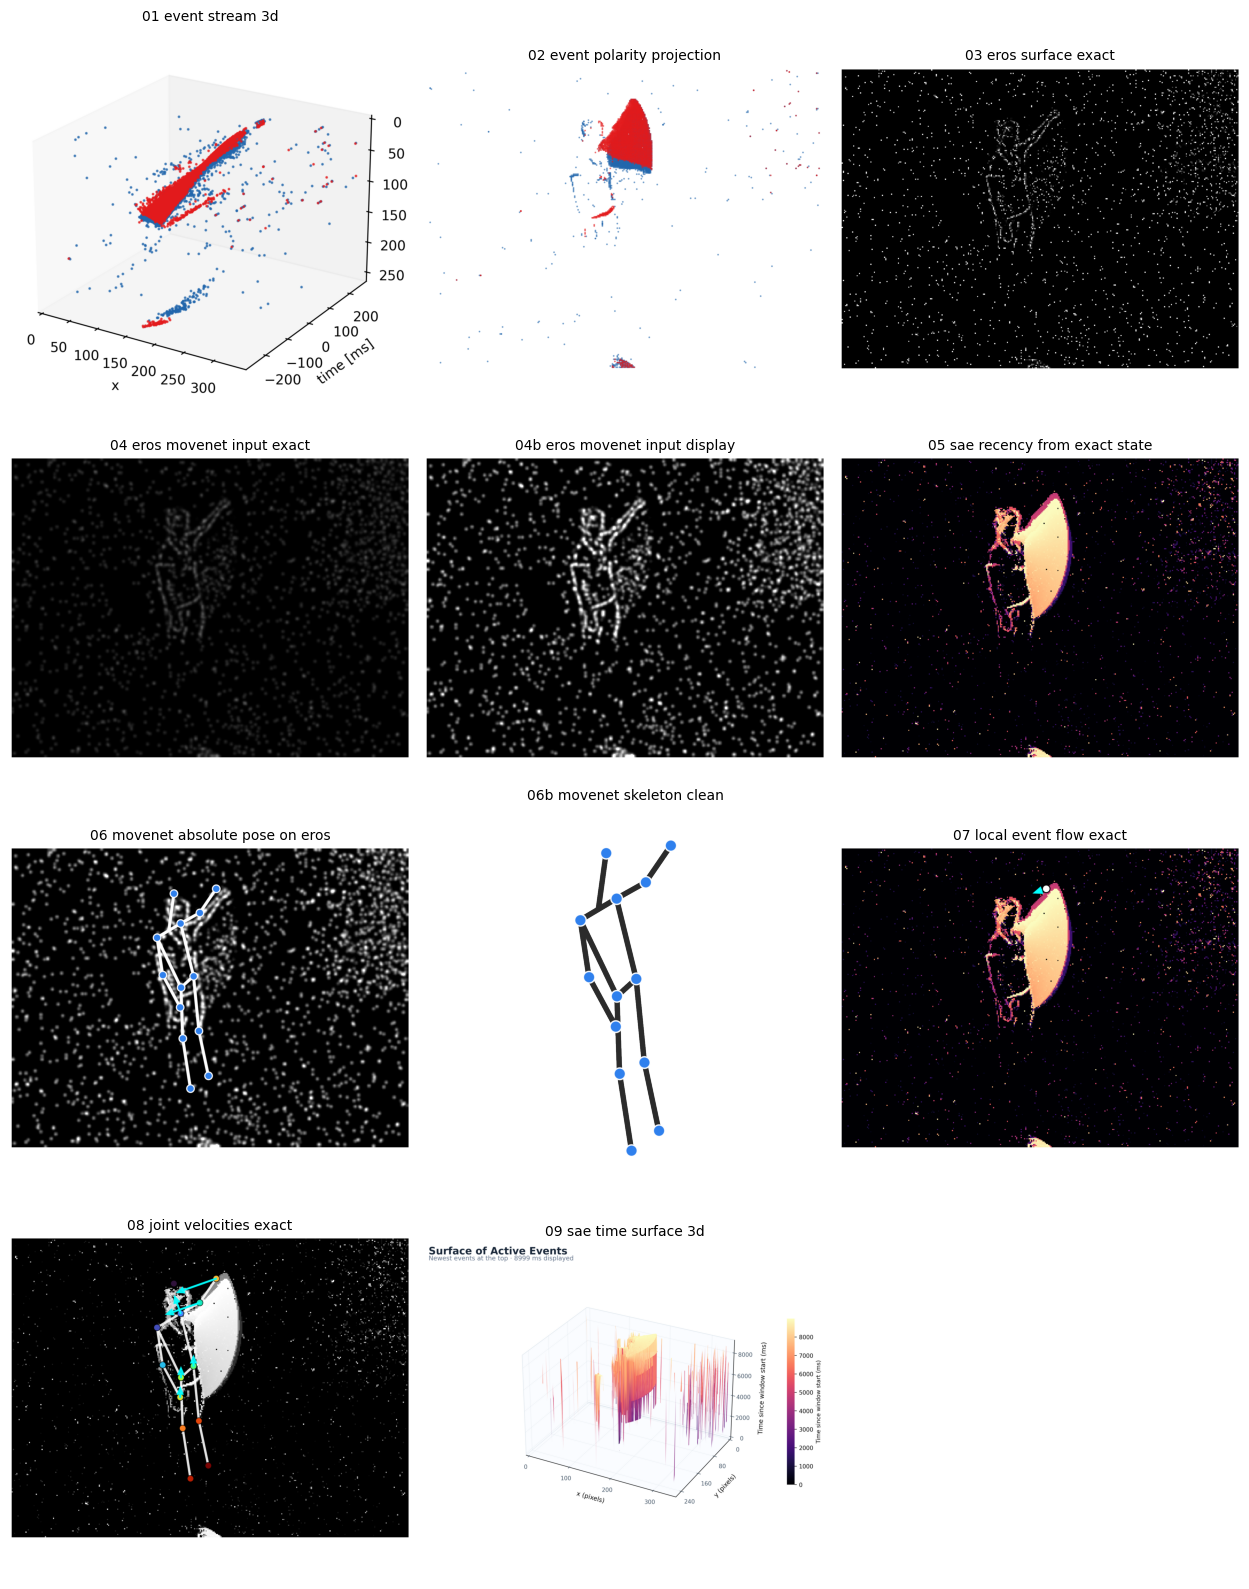

Contact sheet: /tmp/moveenetofk_paper_assets_exact/00_contact_sheet.png
Exact backend metadata: /tmp/moveenetofk_paper_assets_exact/metadata.txt


In [11]:
existing = [Path(p) for p in paths if Path(p).exists()]
cols = 3
rows = max(1, int(math.ceil(len(existing) / cols)))
fig, axes = plt.subplots(rows, cols, figsize=(12.6, 4.0*rows), squeeze=False)
for ax in axes.ravel():
    ax.axis('off')
for ax, path in zip(axes.ravel(), existing):
    img = plt.imread(path)
    ax.imshow(img)
    ax.set_title(path.stem.replace('_', ' '), fontsize=10)
    ax.axis('off')
fig.tight_layout()
contact = OUTPUT_DIR / '00_contact_sheet.png'
fig.savefig(contact, dpi=240, bbox_inches='tight')
plt.show()
print('Contact sheet:', contact)
print('Exact backend metadata:', OUTPUT_DIR / 'metadata.txt')

## Mapping to the paper figure

Use these replacements:

- **Event stream** → `01_event_stream_3d.png`.
- **EROS representation** → `03_eros_surface_exact.png`; `04b_eros_movenet_input_display.png` is the clearer display of the exact blurred MoveEnet input.
- **Absolute 2-D joint detection / skeleton** → `06_movenet_absolute_pose_on_eros.png`, or `06b_movenet_skeleton_clean.png` for a transparent standalone skeleton in the diagram.
- **Surface of Active Events (SAE)** → `05_sae_recency_from_exact_state.png`.
- **Local event-based optical flow** → `07_local_event_flow_exact.png`.
- **Joint velocities** → `08_joint_velocities_exact.png`.

All panels are aligned to the same selected flow-update timestamp and generated from the same recording. With `POSE_CSV=None`, the notebook automatically obtains the 13-joint pose from the same MoveEnet model/checkpoint used by the offline pipeline.

- **3-D SAE time surface** → `09_sae_time_surface_interactive.html` (free rotation), `09_sae_time_surface_3d.png` and `.svg` (static exports).
